# 05 — 적합도 예측 신뢰도 보정 (`results/calib_logistic`)

회귀 모델이 내는 예측 평균 $\mu$ (`fitness_z`) · 가지 간 표준편차 $\sigma$ (`fitness_sd`) 로부터 예측마다 신뢰도 2종을 확률로 계산하는 확률표를 만든다. 보정 자료는 서비스 회귀 모델과 같은 입력 조합(`noseq`)의 **교차검증 예측** 이다. 각 예측은 그 유전자의 genus 를 학습에 쓰지 않은 모델이 낸 값이라, 새 균주를 예측할 때의 오차 양상을 담는다.

| 신뢰도 | 정의 (실측 = 균주 내 z-정규화 `fit_mean`) | 범위 |
|---|---|---|
| `conf_sign` | 실측이 예측과 같은 쪽(균주 평균보다 높음 / 낮음)에 있을 확률 — 방향 신뢰도 | 0 ~ 1 |
| `conf_fit` | 실측이 예측 구간 $\mu \pm \sigma$ 안에 있을 확률 — 구간 적중 확률 | 0 ~ 1 |

| 파일 (`results/calib_logistic/`) | 내용 |
|---|---|
| `calibration.json` | 두 신뢰도의 $(\mu,\ \log\sigma)$ 격자 확률표 (서비스 `assets/` 에 그대로 복사해 쓴다) |
| `check_conf_sign.csv` · `check_conf_fit.csv` | genus 단위 검증 — 예측 확률 구간별 실제 비율 |
| `calibration.png` | 같은 검증의 보정 그림 |

진행: 1 데이터 → 2 적중 판정 → 3 확률표 → 4 genus 단위 검증 → 5 최종 확률표

In [1]:
import os, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from sklearn.ensemble import HistGradientBoostingClassifier
from proteomefit import data
from proteomefit.config import Config

cfg      = Config()                                   # base data 경로
CV_DIR   = '../results/fitpred_ablation/noseq'         # 서비스 회귀 모델과 같은 입력 조합의 교차검증 결과
OUT_DIR  = '../results/calib_logistic'
GRID_MU  = np.round(np.arange(-8, 2.01, 0.1), 2)      # 확률표의 mu 격자 [101]
GRID_LSD = np.round(np.arange(-1.6, 1.21, 0.1), 2)    # 확률표의 log(sd) 격자 [29]
BINS     = [0, .2, .3, .4, .5, .6, .7, .8, .9, 1.01]   # 검증 표의 확률 구간
os.makedirs(OUT_DIR, exist_ok=True)

## 1. 데이터 — 교차검증 예측과 라벨

| 기호 | 형태 | 내용 |
|---|---|---|
| $\mu$ · $\sigma$ | `[n_pred]` | `CV_DIR/fold##_<genus>/inner##/pred.npz` 의 `mu` · `sd` (28 외부 폴드 x 내부 폴드 3개, 시험 genus 샘플 순서) |
| $y$ | `[n_pred]` | 실측 — 균주 내 z-정규화 `fit_mean` (회귀 라벨과 같다) |

$$y_i = \frac{f_i - \bar{f}_{o(i)}}{s_{o(i)}}$$

- $f_i$ — 원본 `fit_mean`, $\bar{f}_o$ · $s_o$ — 균주 $o$ 의 `fit_mean` 평균 · 표준편차
- 예: 균주 평균 $-0.1$, 표준편차 $0.8$ 에서 `fit_mean` = $-0.9$ → $y = -1.0$
- 같은 유전자가 내부 폴드 3개에서 한 번씩 예측되므로 예측 수는 유전자 수의 3배다

In [2]:
# 라벨 - 적합도 수치가 있는 샘플 (회귀 학습 샘플과 같은 순서) [n]
D   = data.load_samples(cfg.base_dir, cfg.label_col, finite_only=True)
fit = D.yb[D.keep]                                             # 원본 적합도 [n]
g   = pd.Series(fit).groupby(D.org)
y   = ((fit - g.transform('mean')) / g.transform('std')).to_numpy()   # 실측 (균주 내 z) [n]

# 교차검증 예측 [n_pred, 4]
rows = []
for d in sorted(glob.glob(f'{CV_DIR}/fold*')):
    genus = os.path.basename(d).split('_', 1)[1]
    te    = np.flatnonzero(D.gen == genus)                     # 시험 샘플 (pred.npz 와 같은 순서)
    for f in sorted(glob.glob(f'{d}/inner*/pred.npz')):
        z = np.load(f)
        rows.append(pd.DataFrame({'mu': z['mu'], 'sd': z['sd'], 'y': y[te], 'genus': genus}))
R = pd.concat(rows, ignore_index=True)
print(f'cross-validation predictions: {len(R):,} | genera {R.genus.nunique()} | genes {len(y):,}')
print(f'mu: median |mu| {R.mu.abs().median():.3f} | sd: median {R.sd.median():.3f}')

cross-validation predictions: 531,951 | genera 28 | genes 177,317
mu: median |mu| 0.456 | sd: median 0.530


## 2. 적중 판정

$$\mathrm{conf\_sign} = P\big(\mathrm{sign}(y) = \mathrm{sign}(\mu)\ \big\vert\ \mu,\ \sigma\big), \qquad \mathrm{conf\_fit} = P\big(\mu - \sigma \le y \le \mu + \sigma\ \big\vert\ \mu,\ \sigma\big)$$

- 두 신뢰도 모두 서비스 결과표에 보이는 값(`fitness_z` · `fitness_sd`)이 실측 `fit_mean` 과 맞을 확률이다
- 예: $\mu = -1.0,\ \sigma = 0.5$ → 구간 $[-1.5,\ -0.5]$
  - 실측 $y = -0.7$ → 방향 적중 · 구간 적중
  - 실측 $y = -0.2$ → 방향 적중 · 구간 빗나감
  - 실측 $y = 0.3$ → 방향 빗나감 · 구간 빗나감
- $\sigma$ 는 미니 MLP 가지들의 의견 차이일 뿐이라 $\pm\sigma$ 가 실측을 68% 포함한다는 보장이 없다. 실제 적중 비율은 $\mu$ · $\sigma$ 에 따라 크게 다르므로(4 절), 교차검증 예측의 적중 여부로 확률을 직접 학습한다
- 실측은 측정 오차를 포함하므로, 두 확률은 전형적인 TnSeq 실험에서 잰 `fit_mean` 과 맞을 확률이다
- 전체 유전자를 쓴다. 측정 오차가 작은 유전자만 고르면 효과가 작은 유전자 쪽으로 치우친다
- `conf_sign` 이 0.5 보다 작으면 예측과 반대 방향일 가능성이 더 높다는 뜻이다

In [3]:
def hits(df):
    """교차검증 예측 표 -> 적중 여부 {'sign': [m], 'fit': [m]} (실측 기준)"""
    return {'sign': (np.sign(df.y) == np.sign(df.mu)).values,         # 실측이 예측과 같은 쪽
            'fit':  (np.abs(df.y - df.mu) <= df.sd).values}           # 실측이 mu +- sd 안

H = hits(R)
print(f"overall hit rate: sign {H['sign'].mean():.3f} | fit {H['fit'].mean():.3f}")

overall hit rate: sign 0.595 | fit 0.538


## 3. 확률표 — 기울기 부스팅

| 단계 | 내용 | 형태 |
|---|---|---|
| 학습 | `HistGradientBoostingClassifier` 로 입력 $(\mu,\ \log\sigma)$ → 적중 여부(예 / 아니오) 분류 | 전체 예측 `[n_pred, 2]` |
| 확률표 | 격자 `GRID_MU` x `GRID_LSD` 위 예측 확률 | `[101, 29]` |
| 적용 | 확률표를 선형 보간 (격자 밖 값은 가장자리로 자른다) | `[n]` |

- $\mu$ 는 부호를 살려 넣는다. 음의 적합도(성장 저해)와 양의 적합도는 오차 양상이 다르다. 예: 약한 음수로 예측된 유전자는 실측이 오히려 균주 평균보다 높은 경우가 많다(4 절)
- 기울기 부스팅은 작은 결정 트리를 차례로 더해 칸마다 적중 비율을 맞춘다. $\mu$ · $\log\sigma$ 의 로지스틱 함수처럼 형태를 미리 정하지 않는다
- `min_samples_leaf` = 1000 으로 잎마다 예측이 충분히 모이게 해 확률이 들쭉날쭉하지 않게 한다
- 예: 확률표에서 $(\mu,\ \log\sigma) = (-1.0,\ -0.7)$ 칸 주변 4 칸의 값을 거리에 따라 섞어 $\sigma = 0.5$ ($\log 0.5 = -0.69$) 의 확률을 얻는다

In [4]:
def fit_table(df, hit, grid_mu, grid_lsd):
    """교차검증 예측 표 · 적중 여부 [m] -> 확률표 [len(grid_mu), len(grid_lsd)] (기울기 부스팅)"""
    X = np.column_stack([df.mu.values, np.log(df.sd.values)])        # [m, 2]
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                       min_samples_leaf=1000, random_state=0).fit(X, hit)
    gm, gs = np.meshgrid(grid_mu, grid_lsd, indexing='ij')
    return m.predict_proba(np.column_stack([gm.ravel(), gs.ravel()]))[:, 1].reshape(gm.shape)


def lookup(table, grid_mu, grid_lsd, mu, sd):
    """확률표 · 예측 평균 · 표준편차 [n] -> 확률 [n] (선형 보간, 격자 밖은 가장자리 값)"""
    f = RegularGridInterpolator((grid_mu, grid_lsd), table)
    mu, lsd = np.asarray(mu, float), np.log(np.asarray(sd, float))   # float32 예측도 격자와 같은 정밀도로
    x = np.column_stack([np.clip(mu, grid_mu[0], grid_mu[-1]), np.clip(lsd, grid_lsd[0], grid_lsd[-1])])
    return f(x)

## 4. genus 단위 검증

확률표도 새 genus 에 맞는지 따로 확인한다. genus $k$ 를 뺀 나머지 예측으로 두 확률표를 만들고, genus $k$ 의 전체 유전자에 적용해 예측 확률과 실제 적중 비율을 확률 구간별로 비교한다.

| 열 | 내용 |
|---|---|
| `n` | 구간 안 예측 수 |
| `predicted` | 구간 안 예측 확률의 평균 |
| `observed` | 구간 안 실제 적중 비율 |

그림은 구간마다 원 하나다. 가로축이 실제 비율, 세로축이 예측 확률이고 원의 넓이는 그 구간의 예측 수에 비례한다. 원이 대각선 위에 있으면 보정이 맞다. 예: 0.75 를 받은 예측 중 실제로 75% 가 적중하면 그 원은 (0.75, 0.75) 에 놓인다. 대각선보다 위에 있으면 확률을 실제보다 높게(과신), 아래에 있으면 낮게 낸 것이다. 큰 원일수록 많은 유전자가 걸린 구간이라 어긋남이 더 중요하다.

마지막 표는 예측 $\mu$ 범위별 평균 확률과 실제 비율이다. 같은 $\lvert\mu\rvert$ 라도 부호에 따라 적중 비율이 다르다.

held-out genus check - conf_sign (all genes)
                 n  predicted  observed
conf_sign                              
[0.3, 0.4)   37776      0.384     0.392
[0.4, 0.5)   82009      0.438     0.430
[0.5, 0.6)   40252      0.554     0.554
[0.6, 0.7)  351140      0.653     0.653
[0.7, 0.8)   20772      0.717     0.702
[0.8, 0.9)       2      0.800     1.000 

held-out genus check - conf_fit (all genes)
                  n  predicted  observed
conf_fit                                
[0.0, 0.2)    43913      0.137     0.136
[0.2, 0.3)    34221      0.251     0.247
[0.3, 0.4)    43804      0.353     0.351
[0.4, 0.5)    65413      0.453     0.456
[0.5, 0.6)    93678      0.553     0.558
[0.6, 0.7)   146088      0.650     0.650
[0.7, 0.8)    87918      0.742     0.744
[0.8, 0.9)    16855      0.826     0.824
[0.9, 1.01)      61      0.905     0.902 

by predicted mu
                    n  conf_sign  sign_hit  conf_fit  fit_hit
mu                                                        

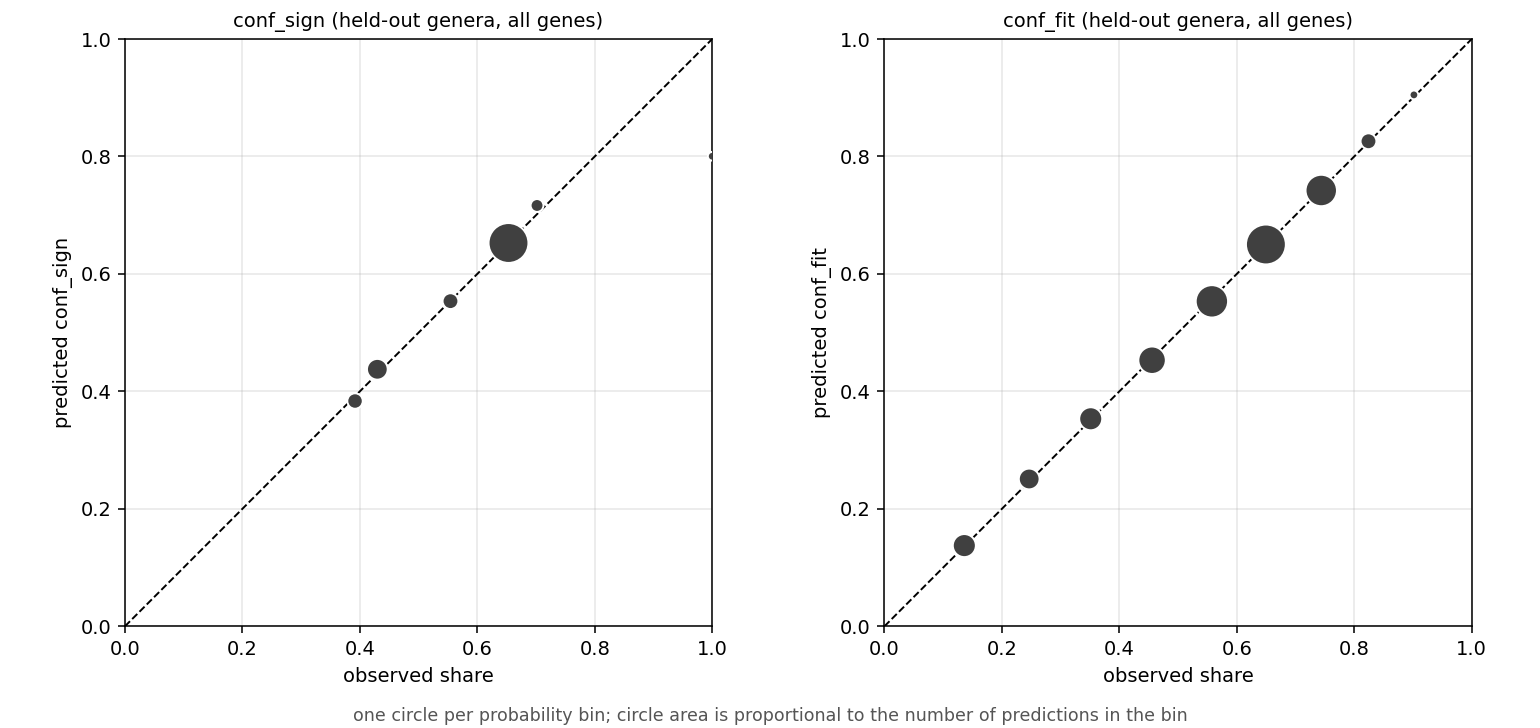

In [5]:
out = []
for genus in R.genus.unique():                                 # genus 하나씩 빼고 학습 -> 뺀 genus 에 적용
    tr, te = R[R.genus != genus], R[R.genus == genus]
    h_tr, h_te = hits(tr), hits(te)
    o = pd.DataFrame({'mu': te.mu.values})
    for k in ('sign', 'fit'):
        o[f'conf_{k}'] = lookup(fit_table(tr, h_tr[k], GRID_MU, GRID_LSD), GRID_MU, GRID_LSD, te.mu.values, te.sd.values)
        o[f'{k}_hit'] = h_te[k]
    out.append(o)
O = pd.concat(out, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, k in zip(axes, ('sign', 'fit')):
    c, h = f'conf_{k}', f'{k}_hit'
    T = O.groupby(pd.cut(O[c], BINS, right=False), observed=True).agg(n=(h, 'size'), predicted=(c, 'mean'), observed=(h, 'mean'))
    T.index = T.index.astype(str)
    T.round(4).to_csv(f'{OUT_DIR}/check_{c}.csv', index_label='bin')
    print(f'held-out genus check - {c} (all genes)'); print(T.round(3).to_string(), '\n')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.scatter(T.observed, T.predicted, s=20 + 400 * T.n / T.n.max(), color='#404040', edgecolor='white', zorder=3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlabel('observed share'); ax.set_ylabel(f'predicted {c}'); ax.set_title(f'{c} (held-out genera, all genes)', fontsize=10)
fig.text(0.5, 0.01, 'one circle per probability bin; circle area is proportional to the number of predictions in the bin',
         ha='center', fontsize=9, color='#555555')
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(f'{OUT_DIR}/calibration.png', dpi=140); plt.close(fig)

# 예측 mu 범위별 평균 확률 · 실제 비율 [8 구간, 5]
M = O.groupby(pd.cut(O.mu, [-99, -3, -2, -1, -.5, 0, .5, 1, 99]), observed=True).agg(
    n=('mu', 'size'), conf_sign=('conf_sign', 'mean'), sign_hit=('sign_hit', 'mean'), conf_fit=('conf_fit', 'mean'), fit_hit=('fit_hit', 'mean'))
print('by predicted mu'); print(M.round(3).to_string())

## 5. 최종 확률표

전체 예측으로 두 확률표를 다시 만들어 `calibration.json` 에 저장한다. 서비스는 이 파일을 `assets/` 에 복사해 예측마다 $\mu$ · $\sigma$ 로 두 확률을 보간한다.

| 키 | 내용 |
|---|---|
| `mu` · `log_sd` | 격자 [101] · [29] |
| `sign` · `fit` | `conf_sign` · `conf_fit` 확률표 [101, 29] |
| `source` · `n_predictions` | 보정 자료 |

In [6]:
tables = {k: fit_table(R, H[k], GRID_MU, GRID_LSD) for k in ('sign', 'fit')}    # 각 [101, 29]
cal = dict(mu=GRID_MU.tolist(), log_sd=GRID_LSD.tolist(),
           sign=tables['sign'].round(4).tolist(), fit=tables['fit'].round(4).tolist(),
           source='fitpred_ablation/noseq', n_predictions=int(len(R)))
with open(f'{OUT_DIR}/calibration.json', 'w', encoding='utf-8') as f:
    json.dump(cal, f)
for k, t in tables.items():
    print(f'conf_{k} table: {t.shape} | range {t.min():.3f} - {t.max():.3f}')

# 예시 - 예측 평균 · 표준편차별 두 확률
ex = pd.DataFrame({'mu': [0.1, 0.6, -0.5, -1.0, -2.0, -4.0], 'sd': [0.5, 0.4, 0.5, 0.5, 0.6, 1.0]})
for k in ('sign', 'fit'):
    ex[f'conf_{k}'] = lookup(tables[k], GRID_MU, GRID_LSD, ex.mu.values, ex.sd.values)
print(ex.round(2).to_string(index=False))
print(f'\nsaved {OUT_DIR}/calibration.json | check_conf_sign.csv | check_conf_fit.csv | calibration.png')

conf_sign table: (101, 29) | range 0.346 - 0.778
conf_fit table: (101, 29) | range 0.049 - 0.917
  mu  sd  conf_sign  conf_fit
 0.1 0.5       0.64      0.70
 0.6 0.4       0.66      0.42
-0.5 0.5       0.40      0.31
-1.0 0.5       0.45      0.14
-2.0 0.6       0.58      0.08
-4.0 1.0       0.66      0.10

saved ../results/calib_logistic/calibration.json | check_conf_sign.csv | check_conf_fit.csv | calibration.png
